# Lab Exercise 7
Name = Aditya Kumar  
Registration Number: 2647203  

### Import Library and Dataset

In [ ]:
# Task 1: Dataset Inspection & Explicit Type Handling
import pandas as pd

# Configure Pandas display options
pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 1000)
pd.set_option("display.precision", 2)

# Load domain dataset
df = pd.read_csv("microgrid_energy_dataset.csv")


#### Dataset Inspection & Type Handling

In [2]:
# Task 1: Dataset Inspection & Explicit Type Handling

print("--- 1. Initial Dataset Inspection ---")
print("Shape of Dataset:", df.shape)
print("\nDataFrame Info:")
df.info()

print("\nDescriptive Statistics (Key Telemetry Metrics):")
display(df[["solar_power_output", "wind_power_output", "battery_soc", "load_demand"]].describe())

print("\nMemory Usage per Column (Bytes):")
print(df.memory_usage(deep=True).head())

# Explicit Type Conversions
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["energy_status"] = df["energy_status"].astype("category")
df["hour_of_day"] = pd.to_numeric(df["hour_of_day"], downcast="integer")

print("\nConverted Column Data Types:")
print(df[["timestamp", "energy_status", "hour_of_day"]].dtypes)


--- 1. Initial Dataset Inspection ---
Shape of Dataset: (5787, 22)

DataFrame Info:
<class 'pandas.DataFrame'>
RangeIndex: 5787 entries, 0 to 5786
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   timestamp                5787 non-null   str    
 1   solar_power_output       5787 non-null   float64
 2   wind_power_output        5787 non-null   float64
 3   solar_irradiance         5787 non-null   float64
 4   temperature              5787 non-null   float64
 5   wind_speed               5787 non-null   float64
 6   humidity                 5787 non-null   float64
 7   cloud_cover              5787 non-null   float64
 8   battery_soc              5787 non-null   float64
 9   battery_charge_power     5787 non-null   float64
 10  battery_discharge_power  5787 non-null   float64
 11  grid_import_power        5787 non-null   float64
 12  grid_export_power        5787 non-null   float64
 13  elect

,solar_power_output,wind_power_output,battery_soc,load_demand
count,5.79e+03,5787.00,5787.00,5787.00
mean,2.48e+02,148.65,54.61,446.49
std,1.45e+02,85.72,25.99,204.33
min,5.82e-03,0.02,10.00,100.07
25%,1.23e+02,75.41,31.92,267.51
50%,2.49e+02,147.58,54.17,447.50
75%,3.73e+02,222.33,77.41,624.01
max,5.00e+02,299.90,100.00,799.99



Memory Usage per Column (Bytes):
Index                    132
timestamp             156249
solar_power_output     46296
wind_power_output      46296
solar_irradiance       46296
dtype: int64

Converted Column Data Types:
timestamp        datetime64[us]
energy_status          category
hour_of_day                int8
dtype: object


#### Subsetting & Data Filtering

In [3]:
# Task 2: Subsetting, Filtering, and Extreme Extraction

# 1. Row slicing using position (iloc) and labels (loc)
first_ten_loc = df.loc[0:9, ["timestamp", "total_power_generation", "load_demand"]]
slice_iloc = df.iloc[5:15, [0, 1, 2, 8]]
print("Position-based Slicing (.iloc [5:15]):\n", slice_iloc.head(3))

# 2. Multi-condition logical filtering (&, |, ~)
# High renewable output (>500 kW), Low Battery (<30%), and NOT in Deficit
critical_buffer = df[(df["total_power_generation"] > 500) & (df["battery_soc"] < 30) & ~(df["energy_status"] == "Deficit")]
print(f"\nFiltered Records (&, |, ~): Found {len(critical_buffer)} critical charging observations.")

# 3. Dynamic Filtering using .query()
query_results = df.query("load_demand > 300 and electricity_price > 8.0 and energy_status == 'Deficit'")
print(f"High-Cost Deficit Events (.query()): Found {len(query_results)} observations.")

# 4. Column subsetting via Regex and isin()
power_cols = df.filter(regex=r".*_power.*").columns.tolist()
print("\nColumns extracted via regex ('.*_power.*'):", power_cols)

peak_hours_df = df[df["hour_of_day"].isin([18, 19, 20, 21])]
print("Observations during Peak Evening Hours (18-21):", len(peak_hours_df))

# 5. Extreme Values: Top 3 Peak Demands and Top 3 Minimum Battery SoC
print("\nTop 3 Peak Grid Demands (.nlargest):")
display(df.nlargest(3, "load_demand")[["timestamp", "load_demand", "total_power_generation", "energy_status"]])

print("Top 3 Lowest Battery SoC Depletions (.nsmallest):")
display(df.nsmallest(3, "battery_soc")[["timestamp", "battery_soc", "grid_import_power", "energy_status"]])


Position-based Slicing (.iloc [5:15]):
             timestamp  solar_power_output  wind_power_output  battery_soc
5 2023-01-01 01:15:00               78.00             289.63        47.68
6 2023-01-01 01:30:00               29.04             274.74        78.10
7 2023-01-01 01:45:00              433.09             150.86        93.52

Filtered Records (&, |, ~): Found 297 critical charging observations.
High-Cost Deficit Events (.query()): Found 1196 observations.

Columns extracted via regex ('.*_power.*'): ['solar_power_output', 'wind_power_output', 'battery_charge_power', 'battery_discharge_power', 'grid_import_power', 'grid_export_power', 'total_power_generation']
Observations during Peak Evening Hours (18-21): 960

Top 3 Peak Grid Demands (.nlargest):


,timestamp,load_demand,total_power_generation,energy_status
2724,2023-01-29 09:00:00,799.99,394.51,Deficit
2923,2023-01-31 10:45:00,799.86,332.60,Deficit
331,2023-01-04 10:45:00,799.83,458.44,Deficit


Top 3 Lowest Battery SoC Depletions (.nsmallest):


,timestamp,battery_soc,grid_import_power,energy_status
2122,2023-01-23 02:30:00,10.00,120.39,Surplus
3557,2023-02-07 01:15:00,10.01,145.43,Deficit
3104,2023-02-02 08:00:00,10.06,77.33,Deficit


#### Data Cleaning & Reshaping

In [4]:
# Task 3: Missing Value Handling, Reshaping, and Method Chaining

# 1. Verification and robust handling of missing values & duplicates
print("Missing values count per column:\n", df.isnull().sum().head())
df = df.drop_duplicates()
df = df.bfill().ffill()  # Forward and backward fill for continuous telemetry

# 2. Unpivoting via pd.melt()
melted_telemetry = pd.melt(
    df.head(5),
    id_vars=["timestamp", "energy_status"],
    value_vars=["solar_power_output", "wind_power_output"],
    var_name="generation_source",
    value_name="power_kw"
)
print("\nUnpivoted Telemetry via pd.melt():\n", melted_telemetry)

# 3. Transposing a summary subset
transposed_view = df[["solar_power_output", "load_demand", "battery_soc"]].describe().T
print("\nTransposed Summary Table (.T):\n", transposed_view)

# 4. Unique Reshaping: Hourly Status Pivot Table
hourly_status_matrix = df.pivot_table(
    index="hour_of_day",
    columns="energy_status",
    values="total_power_generation",
    aggfunc="mean",
    observed=False
)
print("\nPivoted Hourly Generation Matrix (head):\n", hourly_status_matrix.head(4))

# 5. Method Chaining (Combining >= 3 methods in a single statement)
# Chaining: .copy() -> .query() -> .sort_values() -> .assign() -> .head()
chained_analysis = (
    df.copy()
    .query("energy_status == 'Surplus'")
    .sort_values(by="total_power_generation", ascending=False)
    .assign(net_surplus_mw=lambda x: (x["total_power_generation"] - x["load_demand"]) / 1000.0)
    .reset_index(drop=True)
    .head(5)
)
print("\nResult of Method Chaining Pipeline:")
display(chained_analysis[["timestamp", "total_power_generation", "load_demand", "net_surplus_mw"]])


Missing values count per column:
 timestamp             0
solar_power_output    0
wind_power_output     0
solar_irradiance      0
temperature           0
dtype: int64

Unpivoted Telemetry via pd.melt():
             timestamp energy_status   generation_source  power_kw
0 2023-01-01 00:00:00       Surplus  solar_power_output    187.27
1 2023-01-01 00:15:00       Surplus  solar_power_output    475.36
2 2023-01-01 00:30:00       Surplus  solar_power_output    366.00
3 2023-01-01 00:45:00       Surplus  solar_power_output    299.33
4 2023-01-01 01:00:00       Deficit  solar_power_output     78.01
5 2023-01-01 00:00:00       Surplus   wind_power_output    245.90
6 2023-01-01 00:15:00       Surplus   wind_power_output    299.81
7 2023-01-01 00:30:00       Surplus   wind_power_output     63.43
8 2023-01-01 00:45:00       Surplus   wind_power_output     79.55
9 2023-01-01 01:00:00       Deficit   wind_power_output    198.86

Transposed Summary Table (.T):
                      count    mean   

,timestamp,total_power_generation,load_demand,net_surplus_mw
0,2023-01-25 02:30:00,792.89,111.69,0.68
1,2023-01-22 15:30:00,784.44,227.08,0.56
2,2023-02-11 08:30:00,784.40,502.04,0.28
3,2023-02-19 13:45:00,780.34,448.91,0.33
4,2023-01-19 07:00:00,776.55,527.05,0.25


#### Column Engineering & Group Aggregation

In [5]:
# Task 4: Feature Engineering, Aggregations, and Window Operations

# 1. Column Engineering with .assign(), arithmetic, and categorical binning
df = df.assign(
    net_load=df["load_demand"] - df["total_power_generation"],
    bess_utilization_pct=(df["battery_charge_power"] + df["battery_discharge_power"]) / 400.0 * 100.0,
    soc_stress_tier=pd.cut(
        df["battery_soc"],
        bins=[0, 20, 80, 100],
        labels=["Critical_Low", "Nominal_Operating", "Full_Capacity"]
    ),
    price_quantile=pd.qcut(df["electricity_price"], q=4, labels=["Q1_Low", "Q2_Mid", "Q3_High", "Q4_Peak"])
)

# 2. GroupBy with multiple aggregations (.agg, .size, mean, std, sum)
grouped_telemetry = (
    df.groupby("energy_status", observed=False)
    .agg(
        record_count=("load_demand", "size"),
        avg_generation_kw=("total_power_generation", "mean"),
        std_generation=("total_power_generation", "std"),
        total_grid_import_kwh=("grid_import_power", "sum"),
        mean_battery_soc=("battery_soc", "mean")
    )
)
print("--- Energy Status Multi-Aggregation Table ---")
display(grouped_telemetry)

# 3. Rolling Window & Cumulative Operations
# 4-interval rolling average (1 hour window) and cumulative energy produced
df["generation_rolling_4step"] = df["total_power_generation"].rolling(window=4, min_periods=1).mean()
df["cumulative_solar_mwh"] = df["solar_power_output"].cumsum() / 1000.0
df["peak_demand_envelope"] = df["load_demand"].cummax()

print("\nRolling & Cumulative Metrics (Sample Slice):")
display(df[["timestamp", "total_power_generation", "generation_rolling_4step", "cumulative_solar_mwh", "peak_demand_envelope"]].head(4))


--- Energy Status Multi-Aggregation Table ---


,record_count,avg_generation_kw,std_generation,total_grid_import_kwh,mean_battery_soc
energy_status,,,,,
Balanced,761,400.76,160.95,155472.29,55.29
Deficit,2894,320.94,152.14,579715.85,54.40
Surplus,2132,498.93,134.62,420994.18,54.65



Rolling & Cumulative Metrics (Sample Slice):


,timestamp,total_power_generation,generation_rolling_4step,cumulative_solar_mwh,peak_demand_envelope
0,2023-01-01 00:00:00,433.17,433.17,0.19,289.67
1,2023-01-01 00:15:00,775.16,604.17,0.66,353.37
2,2023-01-01 00:30:00,429.43,545.92,1.03,353.37
3,2023-01-01 00:45:00,378.88,504.16,1.33,353.37


#### Vectorized String & Datetime Op

In [6]:
# Task 5: Vectorized String (.str) and Datetime (.dt) Accessors

# 1. Vectorized String Operations
df["status_code"] = df["energy_status"].astype(str).str.upper()
df["status_code_short"] = df["status_code"].str.slice(0, 3)
df["status_len"] = df["status_code"].str.len()
df["status_label"] = df["status_code"].str.replace("SURPLUS", "EXCESS_GREEN_EXPORT")

print("--- Vectorized String Operations (.str) ---")
print(df[["energy_status", "status_code", "status_code_short", "status_label"]].drop_duplicates())

# 2. Vectorized Datetime Component Extraction
df["year"] = df["timestamp"].dt.year
df["month_name"] = df["timestamp"].dt.month_name()
df["day_name"] = df["timestamp"].dt.day_name()
df["quarter"] = df["timestamp"].dt.quarter
df["is_weekend"] = df["timestamp"].dt.dayofweek >= 5

print("\n--- Vectorized Datetime Extraction (.dt) ---")
display(df[["timestamp", "year", "month_name", "day_name", "quarter", "is_weekend"]].head(4))


--- Vectorized String Operations (.str) ---
   energy_status status_code status_code_short         status_label
0        Surplus     SURPLUS               SUR  EXCESS_GREEN_EXPORT
4        Deficit     DEFICIT               DEF              DEFICIT
23      Balanced    BALANCED               BAL             BALANCED

--- Vectorized Datetime Extraction (.dt) ---


,timestamp,year,month_name,day_name,quarter,is_weekend
0,2023-01-01 00:00:00,2023,January,Sunday,1,True
1,2023-01-01 00:15:00,2023,January,Sunday,1,True
2,2023-01-01 00:30:00,2023,January,Sunday,1,True
3,2023-01-01 00:45:00,2023,January,Sunday,1,True


#### Merging & Combining Data

In [7]:
# Task 6: Merging and Concatenating Data

# Construct secondary lookup table for Grid Carbon Tariff and Regulatory Penalty
tariff_lookup = pd.DataFrame({
    "energy_status": ["Surplus", "Deficit", "Balanced"],
    "co2_factor_g_per_kwh": [12.5, 420.0, 55.0],
    "dispatch_priority": ["EXPORT_GRID", "DISPATCH_BESS", "STABLE_FLOAT"],
    "subsidized_rebate": [True, False, True]
})

print("Lookup Reference Table:")
display(tariff_lookup)

# Perform Left Join via pd.merge()
merged_df = pd.merge(df, tariff_lookup, on="energy_status", how="left")
print("\nSuccessfully Merged Data with Regulatory Carbon Lookup:")
display(merged_df[["timestamp", "energy_status", "co2_factor_g_per_kwh", "dispatch_priority", "subsidized_rebate"]].head(4))

# Concatenation demonstration (Vertical Split & Re-combination)
sub_a = merged_df.iloc[:2]
sub_b = merged_df.iloc[2:4]
recombined = pd.concat([sub_a, sub_b], axis=0)
print(f"\nConcatenation Proof: Recombined rows = {len(recombined)}")


Lookup Reference Table:


,energy_status,co2_factor_g_per_kwh,dispatch_priority,subsidized_rebate
0,Surplus,12.5,EXPORT_GRID,True
1,Deficit,420.0,DISPATCH_BESS,False
2,Balanced,55.0,STABLE_FLOAT,True



Successfully Merged Data with Regulatory Carbon Lookup:


,timestamp,energy_status,co2_factor_g_per_kwh,dispatch_priority,subsidized_rebate
0,2023-01-01 00:00:00,Surplus,12.5,EXPORT_GRID,True
1,2023-01-01 00:15:00,Surplus,12.5,EXPORT_GRID,True
2,2023-01-01 00:30:00,Surplus,12.5,EXPORT_GRID,True
3,2023-01-01 00:45:00,Surplus,12.5,EXPORT_GRID,True



Concatenation Proof: Recombined rows = 4


#### Visualization & Display Options

<Axes: title={'center': 'Average Power Generation Across Energy States'}, xlabel='Microgrid Status', ylabel='Average Power (kW)'>

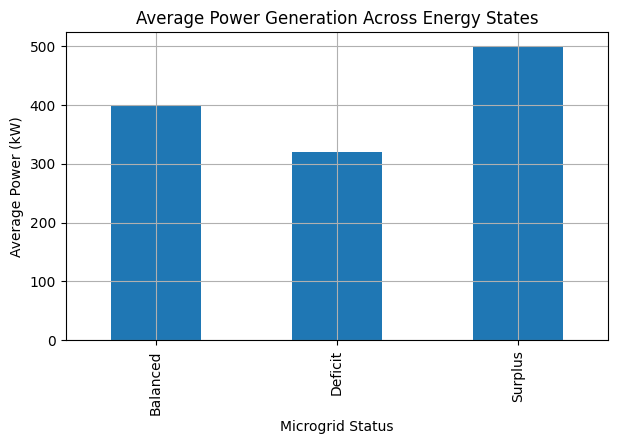

In [8]:
# Task 7: Native Pandas Visualizations (df.plot)

# 1. Native Pandas Bar Chart: Average Generation by Energy Status
merged_df.groupby("energy_status", observed=False)["total_power_generation"].mean().plot(
    kind="bar",
    title="Average Power Generation Across Energy States",
    ylabel="Average Power (kW)",
    xlabel="Microgrid Status",
    grid=True,
    figsize=(7, 4)
)


<Axes: title={'center': 'Real-Time Generation vs 1-Hour Rolling Smoothing and Demand'}, xlabel='Timestamp', ylabel='Power (kW)'>

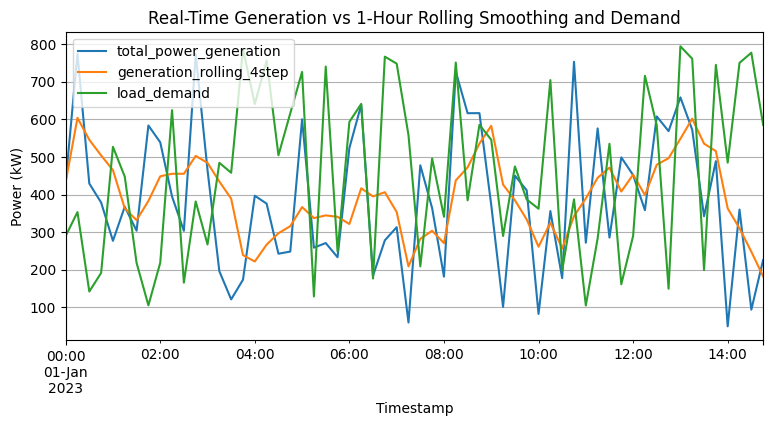

In [9]:
# 2. Native Pandas Line Chart: Generation vs Rolling Average Dispatch Trend
merged_df.head(60).plot(
    x="timestamp",
    y=["total_power_generation", "generation_rolling_4step", "load_demand"],
    kind="line",
    title="Real-Time Generation vs 1-Hour Rolling Smoothing and Demand",
    ylabel="Power (kW)",
    xlabel="Timestamp",
    grid=True,
    figsize=(9, 4)
)


<Axes: title={'center': 'Solar Irradiance vs Solar Power Output Correlation'}, xlabel='Solar Irradiance (W/m²)', ylabel='Solar Output (kW)'>

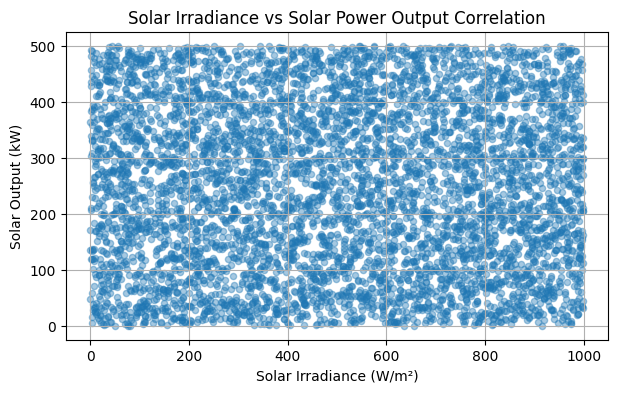

In [10]:
# 3. Native Pandas Scatter Plot: Solar Irradiance vs Solar Output
merged_df.plot(
    kind="scatter",
    x="solar_irradiance",
    y="solar_power_output",
    title="Solar Irradiance vs Solar Power Output Correlation",
    xlabel="Solar Irradiance (W/m²)",
    ylabel="Solar Output (kW)",
    grid=True,
    alpha=0.4,
    figsize=(7, 4)
)


<Axes: title={'center': 'Frequency Distribution of Battery State of Charge (SoC)'}, xlabel='Battery SoC (%)', ylabel='Frequency'>

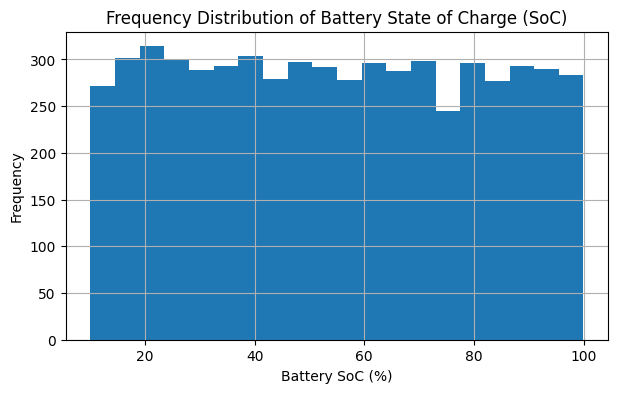

In [11]:
# 4. Native Pandas Histogram: Battery SoC Distribution Across Operating Cycles
merged_df["battery_soc"].plot(
    kind="hist",
    bins=20,
    title="Frequency Distribution of Battery State of Charge (SoC)",
    xlabel="Battery SoC (%)",
    grid=True,
    figsize=(7, 4)
)
